# Supplemental Figure 4, Panel A

Volcano plots showing differential expression due to IFNg or Dex stimulation at 1h or 6h of treatment

*Output: panela_volcano.pdf*

# Setup

In [1]:
#load packages*
library(tidyverse)
library(RColorBrewer)
library(patchwork)
library(ggrastr)
library(here)
here::i_am("figures/SuppFig4/PanelA/PanelA_volcano.ipynb")

theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

sessionInfo()

volcano <- function(table, name, max_x=NULL, max_y=NULL){
    palette <- c(brewer.pal(3,"Paired")[2], "grey", brewer.pal(6, "Paired")[6])
    n <- table(table$change)
    table <- na.omit(table)
    if(is.null(max_x)){
        max_x <- max(abs(table$log2FoldChange))
        }
    if(is.null(max_y)){
       max_y <- max(-log10(table$padj[which(is.finite(-log10(table$padj)))]))
        }
    plot <- ggplot(table, aes(x=log2FoldChange,y=-log10(padj))) +
        geom_vline(xintercept=c(-log2(1.5), log2(1.5)), linetype=2) + 
        geom_hline(yintercept=-log10(0.05), linetype=2) +
        rasterize(geom_point(aes(color=change), size=.5), dpi=300) +
        rasterize(geom_point(data = table %>% filter(change!="ns"), aes(color=change), size=.5), dpi=300) +
        coord_cartesian(xlim=c(-max_x,max_x), ylim=c(0,max_y)) +
        scale_color_manual(values=palette) +
        scale_alpha_manual(values=c(0.5,1)) +
        ggtitle(name, subtitle=paste0("down:",n[1], "; up:", n[3]))
    return(plot)
}

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         ggrastr_1.0.2      patchwork_1.3.0    RColorBrewer_1.1-3
 [5] lubridate_1.9.4    forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4       
 [9] purrr_1.0.2        readr_2.1.5        tidyr_1.3.1        tibble_3.2.1      
[13] ggplot2_3.5.2      tidyverse_2.0.0   

loaded 

# Load data

In [3]:
#read in DEGs
# read in DEGs
ifn_1h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep","IFN_1h_DEGs.tsv"),
  sep = "\t"
)

ifn_6h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus","4rep","IFN_6h_DEGs.tsv"),
  sep = "\t"
)

dex_1h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep", "Dex_1h_DEGs.tsv"),
  sep = "\t"
)

dex_6h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep","Dex_6h_DEGs.tsv"),
  sep = "\t"
)
str(ifn_1h)
str(dex_1h)
str(ifn_6h)
str(dex_6h)

'data.frame':	12572 obs. of  9 variables:
 $ ENSEMBL_ID    : chr  "ENSG00000188976.10" "ENSG00000187961.13" "ENSG00000188290.10" "ENSG00000187608.9" ...
 $ baseMean      : num  1872.28 209.69 2.82 1354.83 1039.07 ...
 $ log2FoldChange: num  0.02648 -0.00938 0.40717 0.06352 0.03496 ...
 $ lfcSE         : num  0.0605 0.1292 0.7463 0.0755 0.0951 ...
 $ stat          : num  0.4378 -0.0726 0.5456 0.8417 0.3678 ...
 $ pvalue        : num  0.662 0.942 0.585 0.4 0.713 ...
 $ padj          : num  1 1 1 1 1 1 1 1 1 1 ...
 $ gene          : chr  "NOC2L" "KLHL17" "HES4" "ISG15" ...
 $ change        : chr  "ns" "ns" "ns" "ns" ...
'data.frame':	12572 obs. of  9 variables:
 $ ENSEMBL_ID    : chr  "ENSG00000188976.10" "ENSG00000187961.13" "ENSG00000188290.10" "ENSG00000187608.9" ...
 $ baseMean      : num  1872.28 209.69 2.82 1354.83 1039.07 ...
 $ log2FoldChange: num  -0.000554 0.204446 -0.325228 -0.093325 -0.014403 ...
 $ lfcSE         : num  0.0609 0.1298 0.8279 0.0762 0.0956 ...
 $ stat          :

# Generate plots

In [46]:
volc_i1 <- volcano(ifn_1h,"IFNy-1h") + coord_cartesian(xlim=c(-6,6), ylim=c(0,125))
volc_i6 <- volcano(ifn_6h,"IFNy-6h") + coord_cartesian(xlim=c(-6,6), ylim=c(0,100))
volc_d1 <- volcano(dex_1h,"Dex-1h") + coord_cartesian(xlim=c(-6,6), ylim=c(0,160))
volc_d6 <- volcano(dex_6h,"Dex-6h", max_y=250) + coord_cartesian(xlim=c(-6,6), ylim=c(0,220))

Coordinate system already present. Adding new coordinate system, which will
replace the existing one.
Coordinate system already present. Adding new coordinate system, which will
replace the existing one.
Coordinate system already present. Adding new coordinate system, which will
replace the existing one.
Coordinate system already present. Adding new coordinate system, which will
replace the existing one.


# Assemble figure panel

Saving 7 x 7 in image


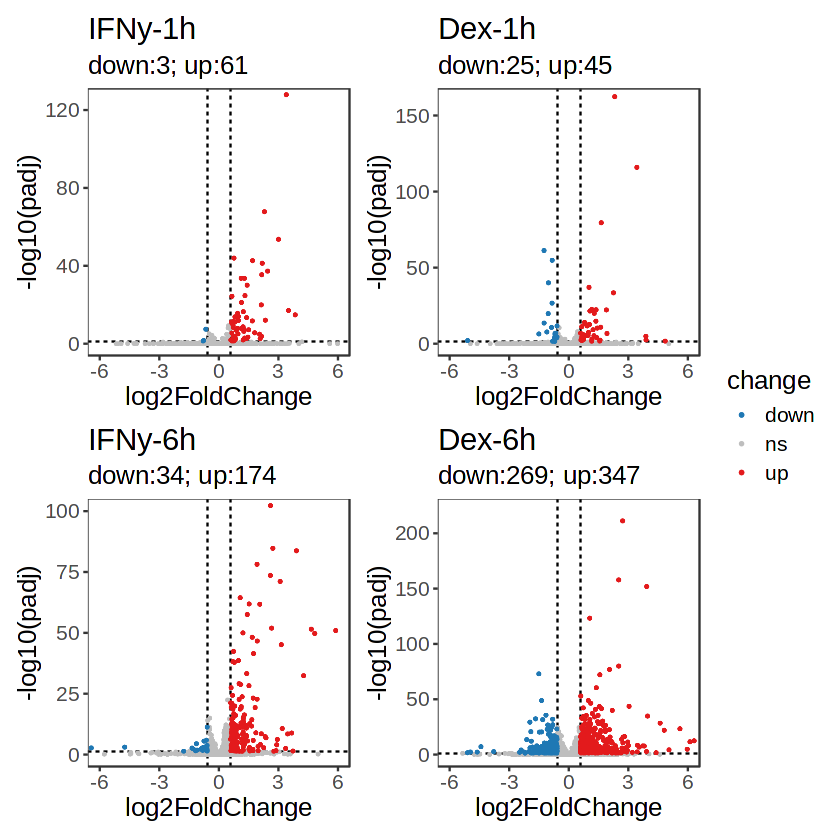

In [48]:
((volc_i1 / volc_i6) | (volc_d1 / volc_d6)) + plot_layout(guides="collect")
ggsave("panela_volcano.pdf")